# Segmentação de clientes com clusterização

**Mini Projeto — IA não supervisionada (clusterização)**

**Dupla**
- Rubens Rodrigues Maranesi — RA00331129
- Pedro Gabriel Takenobu Serafim — RA00340890

**Dataset:** [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis) (Kaggle) — 2.240 clientes de uma rede de supermercados, com dados demográficos, gastos por categoria de produto, canais de compra e resposta a campanhas de marketing.

## 1. Contexto e pergunta

Uma empresa que trata todos os clientes do mesmo jeito desperdiça campanhas: oferece cupom para quem compraria de qualquer forma e manda catálogo caro para quem nunca compra por catálogo. A **segmentação de clientes** resolve isso agrupando pessoas com comportamento parecido.

Não existe um rótulo dizendo a qual segmento cada cliente pertence, então é um problema de aprendizado **não supervisionado**.

**Pergunta do projeto:** quais perfis de cliente existem nessa base, e como cada perfil deveria ser abordado pelo marketing?

**Roteiro**

1. Análise exploratória (EDA) e limpeza
2. Engenharia de features
3. Pré-processamento
4. K-Means (escolha do número de clusters)
5. Comparação com Affinity Propagation e Agrupamento Hierárquico
6. Visualização com PCA
7. Interpretação dos segmentos
8. Conclusões e limitações

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AffinityPropagation, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage

SEED = 42
CORES = ["#0173B2", "#DE8F05", "#029E73", "#CC78BC"]  # azul, laranja, verde, rosa
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)

## 2. Carregando os dados

O arquivo `marketing_campaign.csv` (baixado do Kaggle) está na pasta `data/`. Ele é separado por **tabulação**, não por vírgula.

In [2]:
raw = pd.read_csv("data/marketing_campaign.csv", sep="\t")
print("Formato:", raw.shape)
raw.head()

Formato: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,"58,138.00",0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,"46,344.00",1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,"71,613.00",0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,"26,646.00",1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,"58,293.00",1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


### Dicionário de dados

| Grupo | Coluna | Significado |
|---|---|---|
| Pessoa | `ID` | Identificador do cliente |
| | `Year_Birth` | Ano de nascimento |
| | `Education` | Escolaridade |
| | `Marital_Status` | Estado civil |
| | `Income` | Renda familiar anual |
| | `Kidhome` / `Teenhome` | Nº de crianças / adolescentes em casa |
| | `Dt_Customer` | Data de cadastro do cliente |
| | `Recency` | Dias desde a última compra |
| | `Complain` | 1 se reclamou nos últimos 2 anos |
| Produtos | `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | Valor gasto em cada categoria nos últimos 2 anos |
| Canais | `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | Nº de compras pelo site, catálogo e loja física |
| | `NumDealsPurchases` | Nº de compras com desconto |
| | `NumWebVisitsMonth` | Visitas ao site no último mês |
| Campanhas | `AcceptedCmp1` … `AcceptedCmp5` | 1 se aceitou a oferta da campanha 1 a 5 |
| | `Response` | 1 se aceitou a oferta da última campanha |

## 3. Análise exploratória (EDA)

### 3.1 Qualidade dos dados

In [3]:
print("Valores faltantes por coluna:")
faltantes = raw.isna().sum()
print(faltantes[faltantes > 0])
print("\nIDs duplicados:", raw["ID"].duplicated().sum())
print("\nColunas com um único valor:", [c for c in raw.columns if raw[c].nunique() == 1])

Valores faltantes por coluna:
Income    24
dtype: int64

IDs duplicados: 0

Colunas com um único valor: ['Z_CostContact', 'Z_Revenue']


In [4]:
print("Education:", raw["Education"].value_counts().to_dict())
print("Marital_Status:", raw["Marital_Status"].value_counts().to_dict())

Education: {'Graduation': 1127, 'PhD': 486, 'Master': 370, '2n Cycle': 203, 'Basic': 54}
Marital_Status: {'Married': 864, 'Together': 580, 'Single': 480, 'Divorced': 232, 'Widow': 77, 'Alone': 3, 'Absurd': 2, 'YOLO': 2}


O que encontramos:

- **24 clientes sem renda** (`Income` faltante) — cerca de 1% da base.
- **`Z_CostContact` e `Z_Revenue` são constantes** (mesmo valor em todas as linhas), então não carregam informação.
- **`Marital_Status` tem categorias estranhas**: "Alone", "Absurd" e "YOLO" (7 clientes). Parecem respostas livres de formulário.
- `Dt_Customer` está como texto e precisa virar data.

### 3.2 Valores extremos em idade e renda

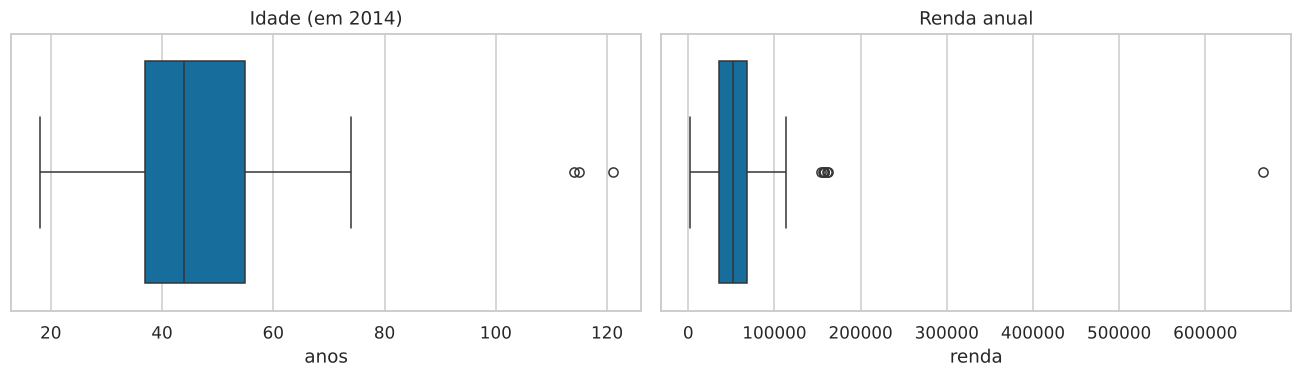

Anos de nascimento mais antigos: [1893, 1899, 1900, 1940, 1941]
Maiores rendas: [666666.0, 162397.0, 160803.0, 157733.0, 157243.0]


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.boxplot(x=2014 - raw["Year_Birth"], ax=axes[0], color="C0")
axes[0].set(title="Idade (em 2014)", xlabel="anos")
sns.boxplot(x=raw["Income"], ax=axes[1], color="C0")
axes[1].set(title="Renda anual", xlabel="renda")
plt.tight_layout()
plt.show()

print("Anos de nascimento mais antigos:", sorted(raw["Year_Birth"])[:5])
print("Maiores rendas:", sorted(raw["Income"].dropna(), reverse=True)[:5])

- Três clientes teriam **mais de 110 anos** (nascidos em 1893, 1899 e 1900): quase certamente erro de digitação.
- Uma renda de **666.666** está muito longe de todas as outras (a segunda maior é cerca de 162 mil) e tem cara de valor inventado.

As demais rendas altas (entre 150 e 162 mil) são plausíveis e foram mantidas.

### 3.3 Limpeza

Decisões:

1. Remover os 24 clientes sem renda. A renda é uma variável central para a segmentação e são poucos casos; imputar a mediana colocaria esses clientes artificialmente no "meio" da base.
2. Remover os 3 clientes com idade impossível e o cliente com renda de 666.666.
3. Descartar `Z_CostContact` e `Z_Revenue`.
4. Agrupar "Alone", "Absurd" e "YOLO" como "Single".

A idade é calculada em relação a **2014**, ano do cadastro mais recente na base (os dados não são atuais).

In [6]:
df = raw.copy()
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "Absurd": "Single", "YOLO": "Single"})

n0 = len(df)
df = df.dropna(subset=["Income"])
df["Age"] = 2014 - df["Year_Birth"]
df = df[(df["Age"] < 100) & (df["Income"] < 600_000)].reset_index(drop=True)
print(f"Clientes: {n0} → {len(df)} ({n0 - len(df)} removidos)")

Clientes: 2240 → 2212 (28 removidos)


## 4. Engenharia de features

Os dados brutos têm muitas colunas parecidas (seis tipos de gasto, três canais de compra, seis campanhas). Criamos variáveis-resumo, mais fáceis de interpretar:

In [7]:
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]

df["Spent"] = df[mnt_cols].sum(axis=1)                                   # gasto total em 2 anos
df["Children"] = df["Kidhome"] + df["Teenhome"]                          # filhos em casa
df["Purchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
df["Tenure_days"] = (df["Dt_Customer"].max() - df["Dt_Customer"]).dt.days  # tempo de casa
df["Campaigns_accepted"] = df[cmp_cols].sum(axis=1)
df["Couple"] = df["Marital_Status"].isin(["Married", "Together"]).astype(int)
df["Education_level"] = df["Education"].map({"Basic": "Básica", "2n Cycle": "Graduação",
                                             "Graduation": "Graduação", "Master": "Pós", "PhD": "Pós"})

df[["Age", "Income", "Children", "Spent", "Purchases", "Tenure_days", "Campaigns_accepted"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,"2,212.00",45.09,11.70,18.00,37.00,44.00,55.00,74.00
Income,"2,212.00","51,958.81","21,527.28","1,730.00","35,233.50","51,371.00","68,487.00","162,397.00"
Children,"2,212.00",0.95,0.75,0.00,0.00,1.00,1.00,3.00
Spent,"2,212.00",607.27,602.51,5.00,69.00,397.00,"1,048.00","2,525.00"
Purchases,"2,212.00",12.57,7.21,0.00,6.00,12.00,18.25,32.00
Tenure_days,"2,212.00",353.71,202.49,0.00,180.00,356.00,529.00,699.00
Campaigns_accepted,"2,212.00",0.45,0.89,0.00,0.00,0.00,1.00,5.00


### 4.1 Distribuições das variáveis principais

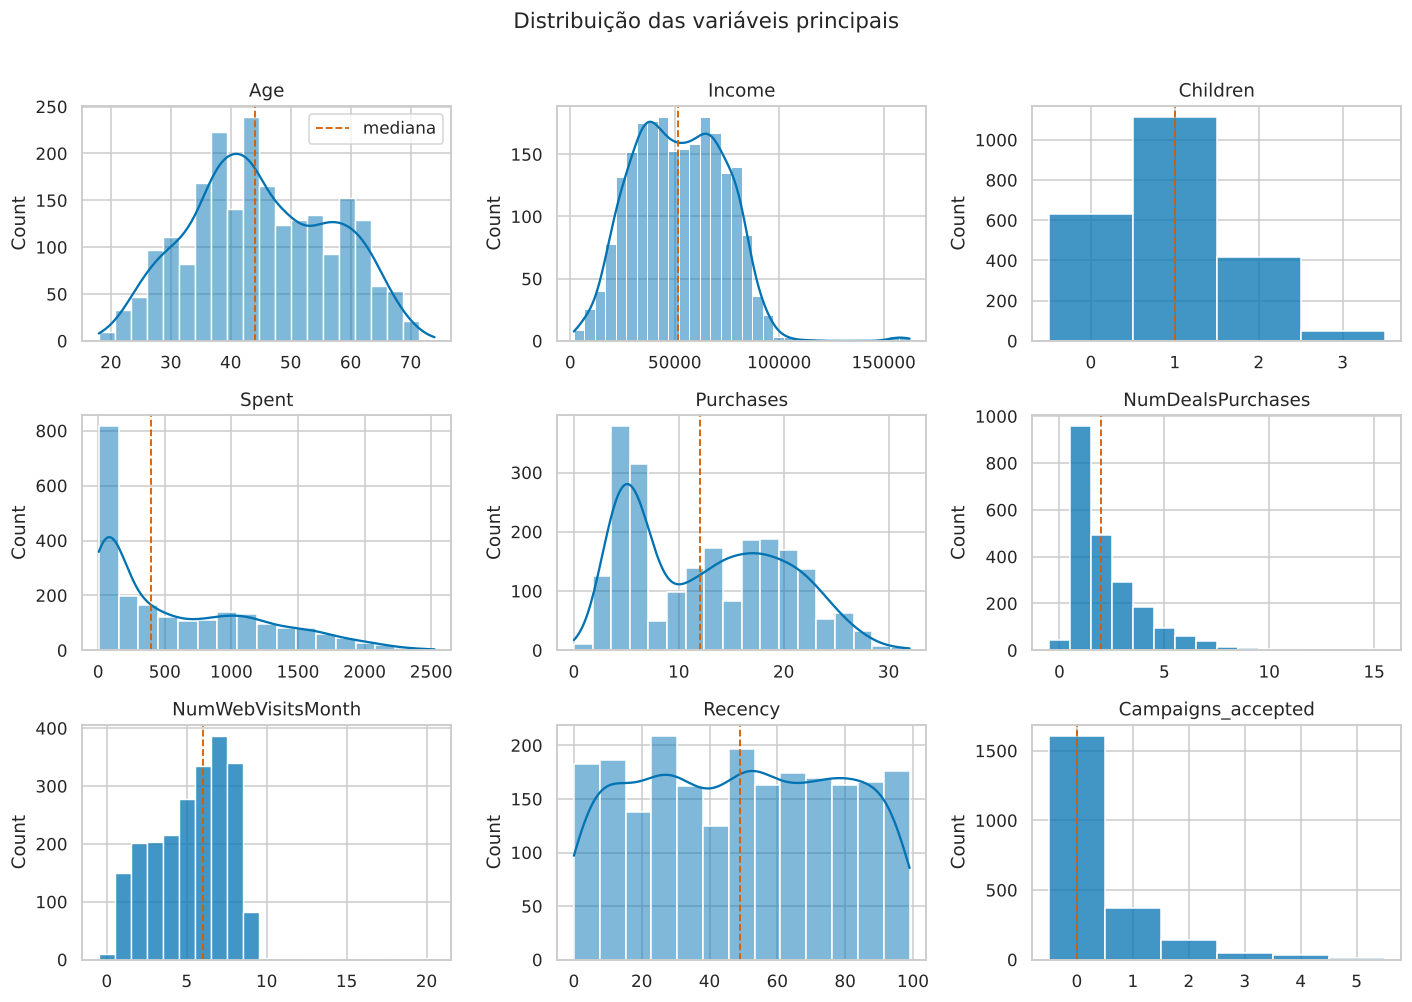

Assimetria:
{'Age': 0.09, 'Income': 0.35, 'Children': 0.41, 'Spent': 0.86, 'Purchases': 0.29, 'NumDealsPurchases': 2.42, 'NumWebVisitsMonth': 0.22, 'Recency': -0.0, 'Campaigns_accepted': 2.44}


In [8]:
principais = ["Age", "Income", "Children", "Spent", "Purchases",
              "NumDealsPurchases", "NumWebVisitsMonth", "Recency", "Campaigns_accepted"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), principais):
    discreta = df[col].nunique() < 20
    sns.histplot(df[col], ax=ax, color="C0", discrete=discreta, kde=not discreta)
    ax.axvline(df[col].median(), color="C3", ls="--", lw=1.2, label="mediana")
    ax.set_title(col); ax.set_xlabel("")
axes[0, 0].legend()
fig.suptitle("Distribuição das variáveis principais", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

print("Assimetria:")
print(df[principais].skew().round(2).to_dict())

- **`Spent` é assimétrica à direita**: a mediana (cerca de 400) fica bem abaixo da média (cerca de 600), porque muitos clientes gastam pouco e uma minoria gasta muito. Esse é justamente o tipo de diferença que a segmentação deve capturar.
- **`Recency` é praticamente uniforme** entre 0 e 99 dias: os clientes estão espalhados igualmente, sem grupos naturais nessa variável.
- **Cerca de 73% dos clientes nunca aceitaram nenhuma campanha.**
- `NumDealsPurchases` também tem cauda longa: poucos clientes fazem muitas compras com desconto.

### 4.2 Para onde vai o dinheiro e por qual canal

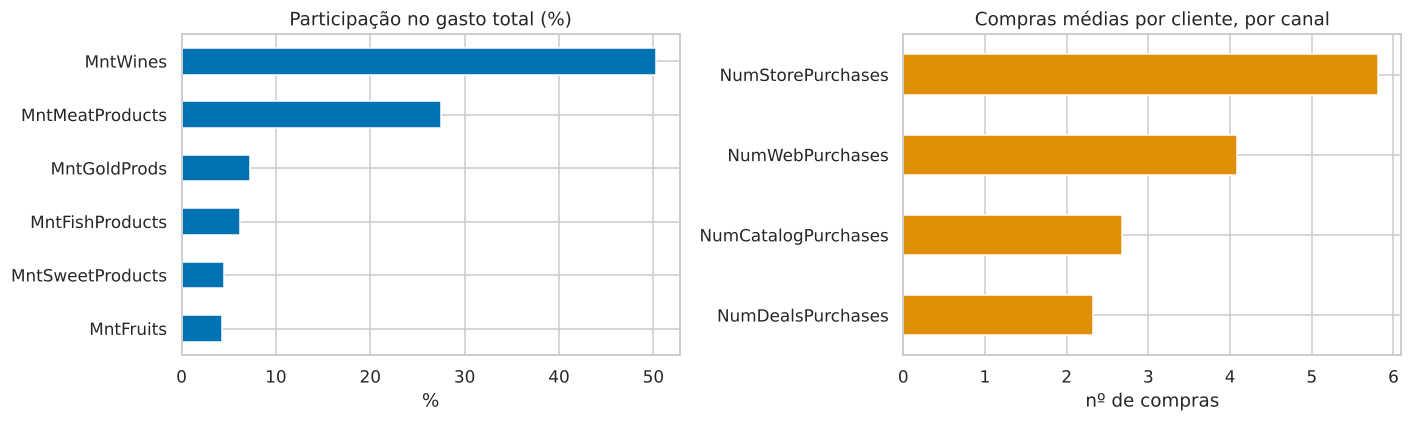

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
gasto = df[mnt_cols].sum().sort_values()
(gasto / gasto.sum() * 100).plot.barh(ax=axes[0], color="C0")
axes[0].set(title="Participação no gasto total (%)", xlabel="%")
canais = df[["NumStorePurchases", "NumWebPurchases", "NumCatalogPurchases", "NumDealsPurchases"]].mean().sort_values()
canais.plot.barh(ax=axes[1], color="C1")
axes[1].set(title="Compras médias por cliente, por canal", xlabel="nº de compras")
plt.tight_layout()
plt.show()

Vinho e carne concentram a maior parte do faturamento, e a loja física é o canal mais usado.

### 4.3 Correlações

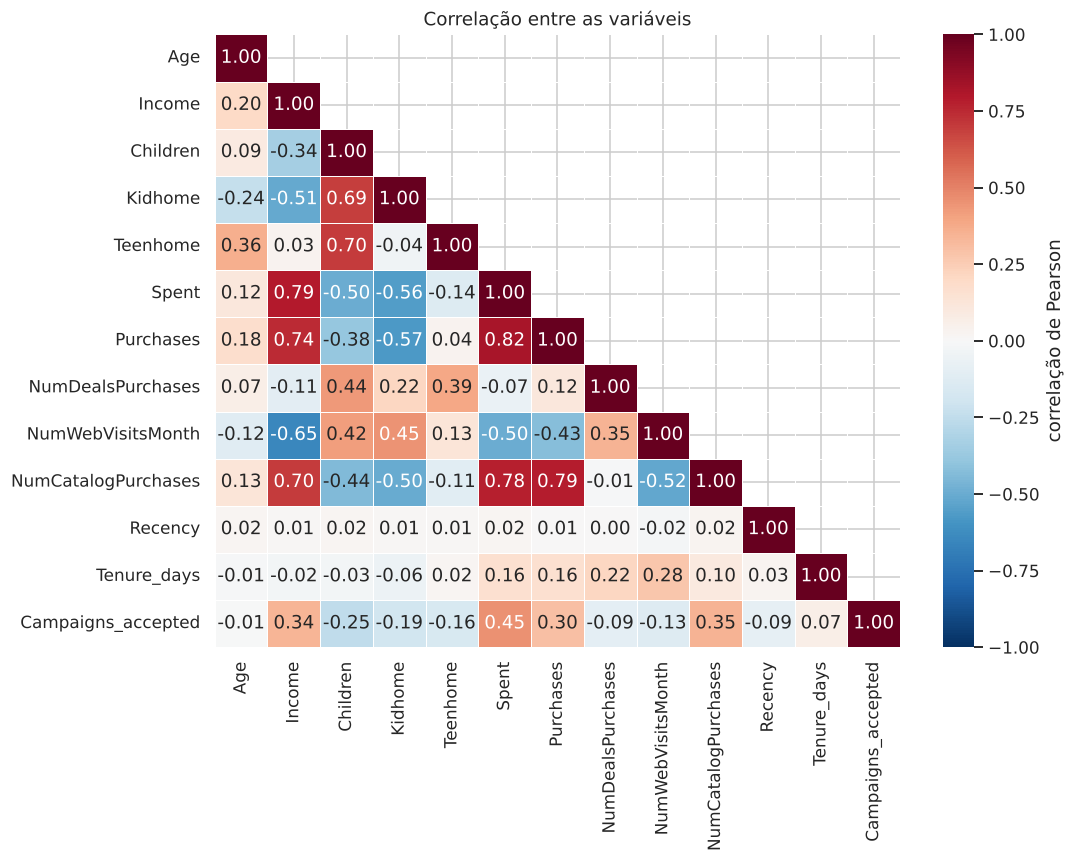

In [10]:
corr_cols = ["Age", "Income", "Children", "Kidhome", "Teenhome", "Spent", "Purchases",
             "NumDealsPurchases", "NumWebVisitsMonth", "NumCatalogPurchases",
             "Recency", "Tenure_days", "Campaigns_accepted"]
corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"label": "correlação de Pearson"})
plt.title("Correlação entre as variáveis")
plt.tight_layout()
plt.show()

As relações mais fortes:

- **Renda, gasto e número de compras andam juntos** (correlações acima de 0,6): quem ganha mais gasta mais.
- **Crianças pequenas em casa (`Kidhome`) puxam o gasto para baixo** e aumentam as visitas ao site.
- **Quem mais visita o site é quem menos gasta**: visitas ao site têm correlação negativa com renda e gasto. Visitar não é comprar.
- **Adolescentes em casa (`Teenhome`) se associam a mais compras com desconto.**
- `Recency` e `Tenure_days` quase não se correlacionam com nada.

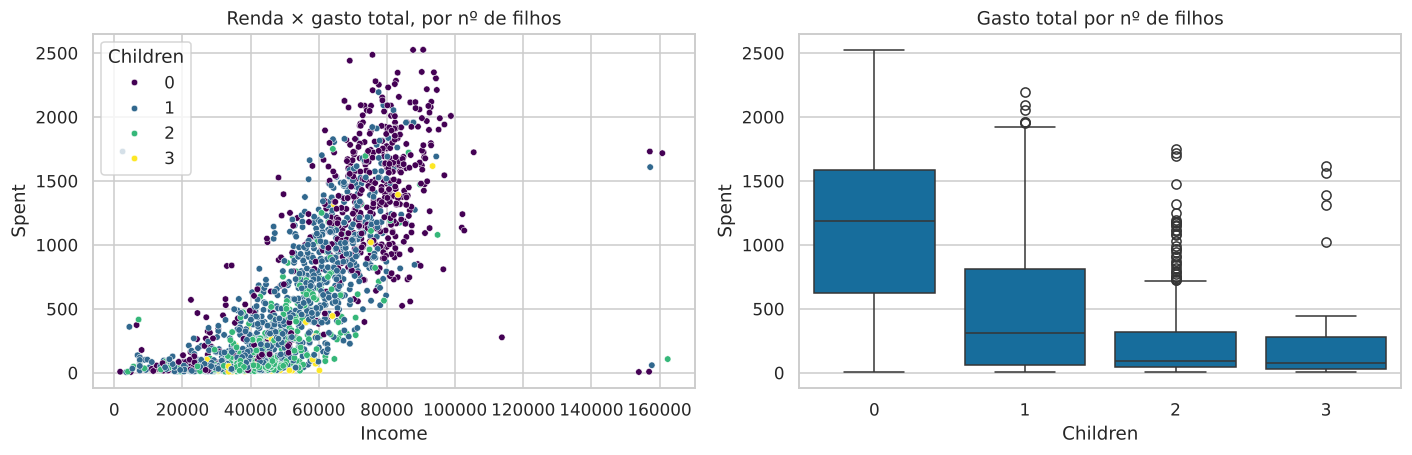

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sns.scatterplot(data=df, x="Income", y="Spent", hue="Children", palette="viridis", s=18, ax=axes[0])
axes[0].set_title("Renda × gasto total, por nº de filhos")
sns.boxplot(data=df, x="Children", y="Spent", color="C0", ax=axes[1])
axes[1].set_title("Gasto total por nº de filhos")
plt.tight_layout()
plt.show()

O gráfico da esquerda já sugere a estrutura: clientes **sem filhos** ocupam a parte alta (renda e gasto altos), e o gasto cai muito à medida que o número de filhos aumenta.

## 5. Pré-processamento

### Seleção de features para a clusterização

Usamos 7 variáveis que descrevem **quem é** o cliente e **como ele compra**:

| Feature | Por quê |
|---|---|
| `Income` | Poder de compra |
| `Age` | Fase da vida |
| `Children` | Composição da família |
| `Spent` | Valor do cliente |
| `Purchases` | Frequência de compra |
| `NumDealsPurchases` | Sensibilidade a promoção |
| `NumWebVisitsMonth` | Engajamento digital |

Deixamos de fora:

- `Recency` e `Tenure_days`: quase sem relação com o resto; só adicionariam ruído à distância.
- As colunas de campanha (`AcceptedCmp*`, `Response`): vamos usá-las **depois**, para verificar se os segmentos respondem de forma diferente ao marketing. Se entrassem no modelo, essa verificação ficaria viciada.
- Os gastos por categoria e as compras por canal, que já estão resumidos em `Spent` e `Purchases` e entram na interpretação.
- Variáveis categóricas (escolaridade, estado civil), que também ficam para a interpretação.

Em seguida padronizamos com `StandardScaler`, para que renda (dezenas de milhares) e filhos (0 a 3) tenham o mesmo peso no cálculo de distância.

In [12]:
features = ["Income", "Age", "Children", "Spent", "Purchases", "NumDealsPurchases", "NumWebVisitsMonth"]
X_scaled = StandardScaler().fit_transform(df[features])
pd.DataFrame(X_scaled, columns=features).describe().loc[["mean", "std", "min", "max"]]

,Income,Age,Children,Spent,Purchases,NumDealsPurchases,NumWebVisitsMonth
mean,-0.00,0.00,0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.33,-2.32,-1.26,-1.00,-1.74,-1.21,-2.19
max,5.13,2.47,2.74,3.18,2.70,6.59,6.05


## 6. K-Means

Testamos k de 2 a 10 e comparamos inércia (cotovelo), silhouette (maior é melhor) e Davies-Bouldin (menor é melhor).

In [13]:
resultados_k = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    resultados_k.append({
        "k": k,
        "inércia": km.inertia_,
        "silhouette": silhouette_score(X_scaled, km.labels_),
        "davies_bouldin": davies_bouldin_score(X_scaled, km.labels_),
        "tamanhos": sorted(np.bincount(km.labels_).tolist(), reverse=True),
    })
resultados_k = pd.DataFrame(resultados_k).set_index("k")
resultados_k

,inércia,silhouette,davies_bouldin,tamanhos
k,,,,
2,"9,695.43",0.35,1.19,"[1287, 925]"
3,"7,951.24",0.30,1.34,"[1017, 677, 518]"
4,"7,056.82",0.26,1.41,"[668, 608, 472, 464]"
5,"6,219.12",0.25,1.42,"[626, 508, 492, 394, 192]"
6,"5,688.21",0.24,1.36,"[613, 477, 384, 284, 267, 187]"
7,"5,227.03",0.25,1.33,"[535, 384, 329, 275, 258, 254, 177]"
8,"4,990.39",0.25,1.34,"[528, 363, 303, 274, 258, 248, 195, 43]"
9,"4,764.01",0.24,1.40,"[516, 297, 251, 236, 235, 227, 219, 186, 45]"
10,"4,583.53",0.24,1.40,"[496, 300, 234, 233, 190, 181, 179, 177, 177, 45]"


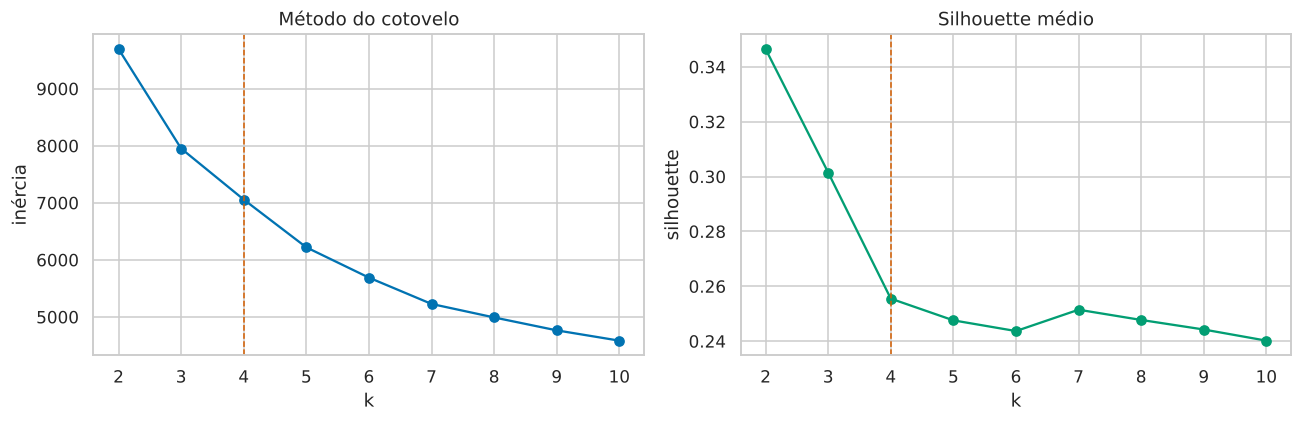

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(resultados_k.index, resultados_k["inércia"], marker="o")
axes[0].set(title="Método do cotovelo", xlabel="k", ylabel="inércia")
axes[1].plot(resultados_k.index, resultados_k["silhouette"], marker="o", color="C2")
axes[1].set(title="Silhouette médio", xlabel="k", ylabel="silhouette")
for ax in axes:
    ax.axvline(4, color="C3", ls="--", lw=1)
plt.tight_layout()
plt.show()

### Comparando k = 2, 3 e 4 na prática

As métricas favorecem poucos clusters: o silhouette é máximo em k = 2 e cai aos poucos. Mas uma métrica alta não garante uma segmentação útil, então olhamos o que cada opção significa:

In [15]:
for k in [2, 3, 4]:
    rot = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled)
    print(f"\nk = {k}")
    display(df[features].groupby(rot).mean().round(1).assign(clientes=np.bincount(rot)))


k = 2


,Income,Age,Children,Spent,Purchases,NumDealsPurchases,NumWebVisitsMonth,clientes
0,"71,789.60",47.20,0.50,"1,194.30",19.40,1.90,3.60,925
1,"37,705.90",43.60,1.30,185.30,7.70,2.70,6.50,1287



k = 3


,Income,Age,Children,Spent,Purchases,NumDealsPurchases,NumWebVisitsMonth,clientes
0,"74,818.30",46.60,0.30,"1,275.70",19.10,1.20,2.90,677
1,"34,454.40",42.30,1.20,104.40,6.10,1.90,6.40,1017
2,"56,449.40",48.60,1.30,720.90,16.80,4.70,6.30,518



k = 4


,Income,Age,Children,Spent,Purchases,NumDealsPurchases,NumWebVisitsMonth,clientes
0,"75,103.50",46.60,0.30,"1,278.30",19.10,1.20,2.90,668
1,"30,186.80",36.70,0.80,107.80,6.10,1.70,6.80,608
2,"57,378.70",48.00,1.30,775.80,17.50,4.70,6.40,472
3,"41,654.00",51.00,1.80,124.10,6.70,2.30,5.90,464


- **k = 2** separa apenas "gasta muito" de "gasta pouco". É óbvio e pouco acionável.
- **k = 3** acrescenta um grupo intermediário de famílias que compram muito com desconto.
- **k = 4** divide os clientes de gasto baixo em dois perfis bem diferentes: **jovens de renda baixa com filhos pequenos** e **pais mais velhos com famílias maiores**. Para o marketing, esses dois grupos pedem abordagens distintas.

Também conferimos se k = 4 é **estável**, isto é, se o resultado muda quando trocamos a semente aleatória do K-Means:

In [16]:
rotulos_seeds = [KMeans(n_clusters=4, n_init=10, random_state=s).fit_predict(X_scaled) for s in range(10)]
estab = [adjusted_rand_score(rotulos_seeds[0], r) for r in rotulos_seeds[1:]]
print(f"ARI entre execuções com sementes diferentes: mínimo {min(estab):.3f}, média {np.mean(estab):.3f}")

ARI entre execuções com sementes diferentes: mínimo 0.956, média 0.980


O resultado é praticamente o mesmo em todas as execuções (ARI próximo de 1), então os 4 grupos não são um acaso da inicialização.

**Escolhemos k = 4.** Abrimos mão de um pouco de silhouette (0,26 contra 0,30 em k = 3) em troca de segmentos mais úteis para o negócio. Essa troca é registrada nas limitações.

In [17]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_scaled)

# Renumera os clusters em ordem decrescente de gasto médio:
# cluster 0 = quem mais gasta, cluster 3 = quem menos gasta.
def ordenar_por_gasto(rotulos):
    ordem = df.groupby(rotulos)["Spent"].mean().sort_values(ascending=False).index
    mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
    return pd.Series(rotulos).map(mapa).values

df["cluster_kmeans"] = ordenar_por_gasto(kmeans.labels_)
print("Silhouette (k=4):", round(silhouette_score(X_scaled, df["cluster_kmeans"]), 3))
df["cluster_kmeans"].value_counts().sort_index()

Silhouette (k=4): 0.256


cluster_kmeans
0    668
1    472
2    464
3    608
Name: count, dtype: int64

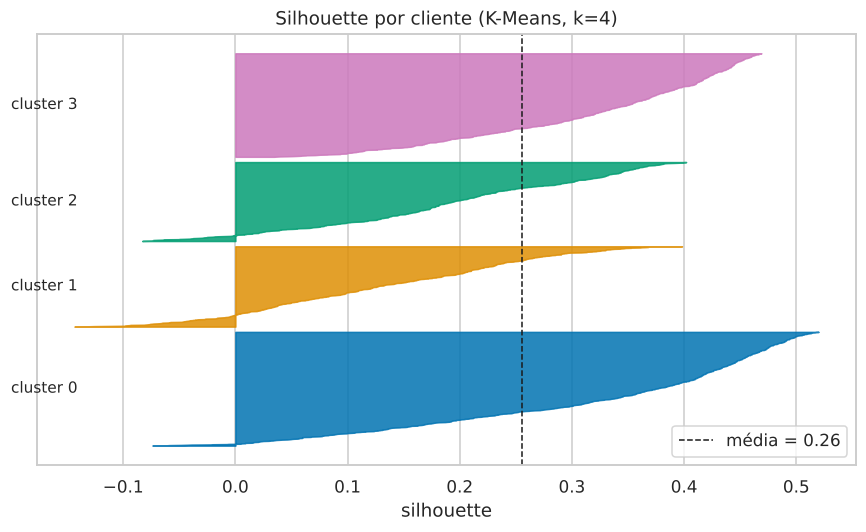

Clientes com silhouette negativo, por cluster:
{0: '1.6%', 1: '14.8%', 2: '7.5%', 3: '0.0%'}


In [18]:
sil = silhouette_samples(X_scaled, df["cluster_kmeans"])
fig, ax = plt.subplots(figsize=(8, 5))
y0 = 10
for c in range(K):
    vals = np.sort(sil[df["cluster_kmeans"] == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, color=CORES[c], alpha=.85)
    ax.text(-0.2, y0 + len(vals) / 2, f"cluster {c}", va="center", fontsize=10)
    y0 += len(vals) + 30
ax.axvline(sil.mean(), color="k", ls="--", lw=1, label=f"média = {sil.mean():.2f}")
ax.set(xlabel="silhouette", yticks=[], title="Silhouette por cliente (K-Means, k=4)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Clientes com silhouette negativo, por cluster:")
print(pd.Series(sil < 0).groupby(df["cluster_kmeans"]).mean().map("{:.1%}".format).to_dict())

## 7. Comparando com outros algoritmos

### 7.1 Affinity Propagation

O Affinity Propagation **não recebe o número de clusters**. Os pontos trocam "mensagens" até elegerem alguns clientes reais como **exemplares** de cada grupo. Quantos grupos surgem depende do parâmetro `preference`: quanto mais negativo, menos exemplares.

Com 2.212 clientes ele ainda roda rápido, mas sua memória cresce com o quadrado do número de pontos (a matriz de similaridade tem 2.212 × 2.212 posições). Usamos `damping=0.9` para ajudar a convergência.

In [19]:
ap_padrao = AffinityPropagation(random_state=SEED).fit(X_scaled)
print(f"Com parâmetros padrão: {len(ap_padrao.cluster_centers_indices_)} clusters")

linhas = []
for pref in [-100, -200, -400, -800, -1000, -1500, -2000]:
    ap = AffinityPropagation(preference=pref, damping=0.9, max_iter=1000, random_state=SEED).fit(X_scaled)
    n = len(ap.cluster_centers_indices_)
    linhas.append({
        "preference": pref,
        "nº clusters": n,
        "silhouette": silhouette_score(X_scaled, ap.labels_) if n > 1 else np.nan,
        "tamanhos": sorted(np.bincount(ap.labels_).tolist(), reverse=True),
    })
pd.DataFrame(linhas).set_index("preference")

Com parâmetros padrão: 88 clusters


,nº clusters,silhouette,tamanhos
preference,,,
-100,20,0.18,"[249, 208, 198, 141, 134, 123, 122, 114, 109, ..."
-200,9,0.23,"[513, 288, 237, 236, 233, 205, 205, 158, 137]"
-400,7,0.25,"[578, 395, 294, 263, 252, 249, 181]"
-800,5,0.24,"[692, 502, 492, 361, 165]"
-1000,4,0.25,"[709, 578, 492, 433]"
-1500,3,0.29,"[981, 664, 567]"
-2000,2,0.34,"[1471, 741]"


Com a configuração padrão o algoritmo gera dezenas de clusters, impossíveis de usar como segmentos. Conforme o `preference` fica mais negativo, o número cai. Usamos **`preference = -1000`**, que chega a 4 grupos — o mesmo número do K-Means, para podermos compará-los.

In [20]:
ap = AffinityPropagation(preference=-1000, damping=0.9, max_iter=1000, random_state=SEED).fit(X_scaled)
df["cluster_ap"] = ordenar_por_gasto(ap.labels_)

exemplares = df.iloc[ap.cluster_centers_indices_].copy()
print("Cliente exemplar de cada cluster (um cliente real que representa o grupo):")
exemplares[["cluster_ap"] + features].sort_values("cluster_ap").set_index("cluster_ap")

Cliente exemplar de cada cluster (um cliente real que representa o grupo):


,Income,Age,Children,Spent,Purchases,NumDealsPurchases,NumWebVisitsMonth
cluster_ap,,,,,,,
0,"74,538.00",43,0,1461,21,1,3
1,"65,814.00",48,1,747,20,3,5
2,"43,602.00",48,2,68,6,3,6
3,"33,183.00",39,1,120,7,2,7


Os exemplares são uma vantagem do Affinity Propagation: em vez de um centróide abstrato, temos um "cliente típico" real para apresentar à equipe de marketing.

### 7.2 Agrupamento hierárquico (Ward)

O hierárquico começa com cada cliente sozinho e vai juntando os mais parecidos. Como 2.212 folhas não cabem no gráfico, o dendrograma mostra só as últimas 30 junções.

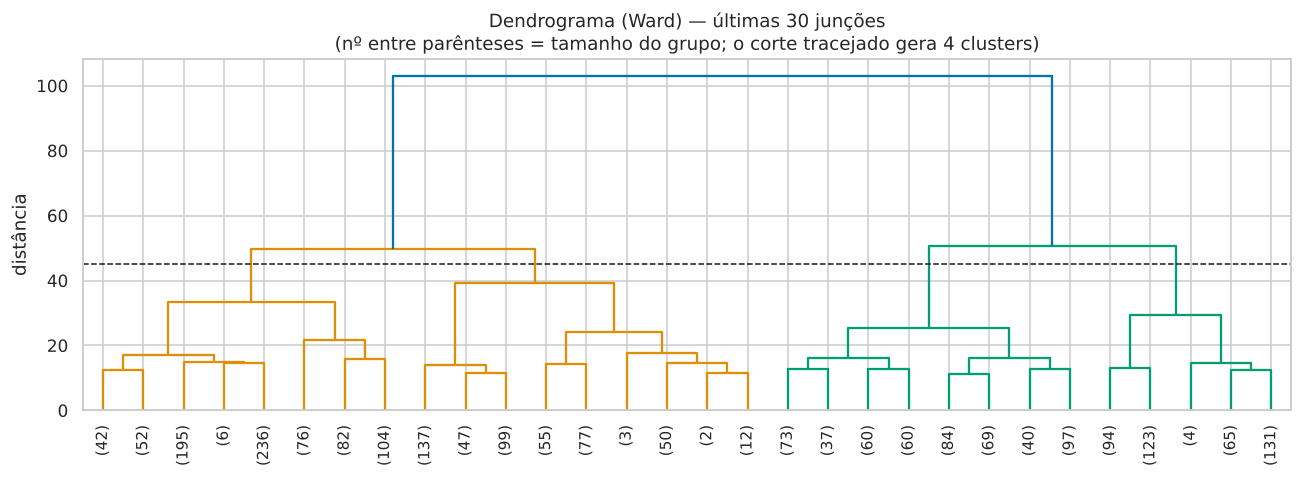

cluster_hier
0    417
1    520
2    482
3    793
Name: count, dtype: int64

In [21]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90)
plt.axhline(45, color="k", ls="--", lw=1)
plt.title("Dendrograma (Ward) — últimas 30 junções\n(nº entre parênteses = tamanho do grupo; o corte tracejado gera 4 clusters)")
plt.ylabel("distância")
plt.tight_layout()
plt.show()

ag = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X_scaled)
df["cluster_hier"] = ordenar_por_gasto(ag.labels_)
df["cluster_hier"].value_counts().sort_index()

### 7.3 Comparação

In [22]:
modelos = {
    "K-Means (k=4)": "cluster_kmeans",
    "Affinity Propagation (pref=-1000)": "cluster_ap",
    "Hierárquico Ward (4)": "cluster_hier",
}
comp = pd.DataFrame([{
    "modelo": nome,
    "silhouette (maior = melhor)": silhouette_score(X_scaled, df[col]),
    "Davies-Bouldin (menor = melhor)": davies_bouldin_score(X_scaled, df[col]),
    "Calinski-Harabasz (maior = melhor)": calinski_harabasz_score(X_scaled, df[col]),
    "tamanhos (cluster 0 → 3)": df[col].value_counts().sort_index().tolist(),
} for nome, col in modelos.items()]).set_index("modelo")
comp

,silhouette (maior = melhor),Davies-Bouldin (menor = melhor),Calinski-Harabasz (maior = melhor),tamanhos (cluster 0 → 3)
modelo,,,,
K-Means (k=4),0.26,1.41,878.92,"[668, 472, 464, 608]"
Affinity Propagation (pref=-1000),0.25,1.47,850.20,"[492, 578, 433, 709]"
Hierárquico Ward (4),0.22,1.58,750.86,"[417, 520, 482, 793]"


In [23]:
cols = list(modelos.values())
ari = pd.DataFrame([[adjusted_rand_score(df[a], df[b]) for b in cols] for a in cols],
                   index=modelos.keys(), columns=modelos.keys())
print("Concordância entre os modelos (Adjusted Rand Index: 1 = idênticos, 0 = aleatório)")
display(ari)
print("K-Means (linhas) × Affinity Propagation (colunas)")
display(pd.crosstab(df["cluster_kmeans"], df["cluster_ap"]))
print("K-Means (linhas) × Hierárquico (colunas)")
display(pd.crosstab(df["cluster_kmeans"], df["cluster_hier"]))

Concordância entre os modelos (Adjusted Rand Index: 1 = idênticos, 0 = aleatório)


,K-Means (k=4),Affinity Propagation (pref=-1000),Hierárquico Ward (4)
K-Means (k=4),1.00,0.62,0.49
Affinity Propagation (pref=-1000),0.62,1.00,0.64
Hierárquico Ward (4),0.49,0.64,1.00


K-Means (linhas) × Affinity Propagation (colunas)


cluster_ap,0,1,2,3
cluster_kmeans,,,,
0,492,176,0,0
1,0,363,75,34
2,0,31,358,75
3,0,8,0,600


K-Means (linhas) × Hierárquico (colunas)


cluster_hier,0,1,2,3
cluster_kmeans,,,,
0,417,216,0,35
1,0,295,137,40
2,0,9,328,127
3,0,0,17,591


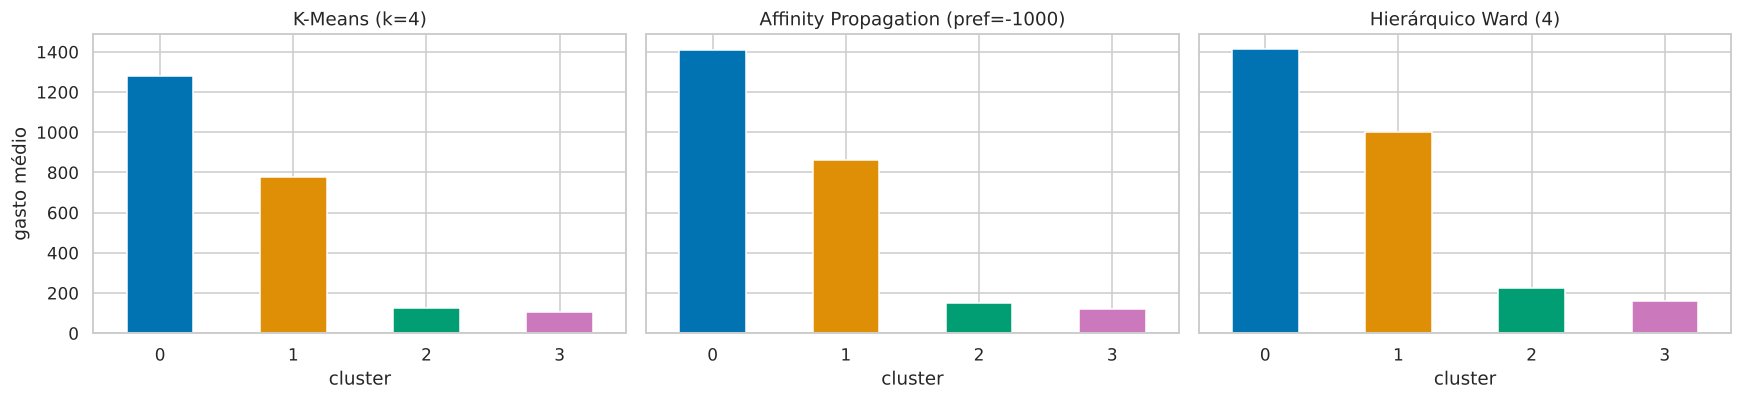

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (nome, col) in zip(axes, modelos.items()):
    df.groupby(col)["Spent"].mean().plot.bar(ax=ax, color=CORES, rot=0)
    ax.set(title=nome, xlabel="cluster", ylabel="gasto médio")
plt.tight_layout()
plt.show()

Os números exatos de concordância estão nas tabelas acima. Os pontos principais:

- **Os três algoritmos encontram a mesma estrutura geral**: um grupo de alto gasto, um de gasto intermediário e dois de gasto baixo. As diferenças estão em quantos clientes de fronteira vão para cada lado.
- K-Means e Affinity Propagation têm métricas muito próximas. O hierárquico fica um pouco atrás no silhouette.
- Nenhum algoritmo consegue silhouette alto: os clientes formam um contínuo, e os segmentos são faixas desse contínuo.

Seguimos com o **K-Means** para a interpretação: é estável, tem métricas iguais ou melhores que as alternativas e é o mais simples de explicar e de aplicar a clientes novos (basta calcular o centróide mais próximo).

## 8. Visualização com PCA

In [25]:
pca = PCA(random_state=SEED).fit(X_scaled)
var = pca.explained_variance_ratio_
print("Variância explicada por componente:", np.round(var, 3))
print(f"PC1 + PC2 = {var[:2].sum():.1%}")
pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"]).sort_values("PC1")

Variância explicada por componente: [0.479 0.203 0.136 0.085 0.052 0.025 0.02 ]
PC1 + PC2 = 68.2%


,PC1,PC2
NumWebVisitsMonth,-0.41,0.19
Children,-0.34,0.44
NumDealsPurchases,-0.13,0.70
Age,0.10,0.39
Purchases,0.46,0.30
Income,0.49,0.15
Spent,0.49,0.14


- **PC1** é o eixo de **valor do cliente**: renda, gasto e número de compras de um lado; filhos e visitas ao site do outro.
- **PC2** é dominado por **idade, filhos e compras com desconto**: separa famílias mais velhas e caçadoras de promoção dos clientes jovens.

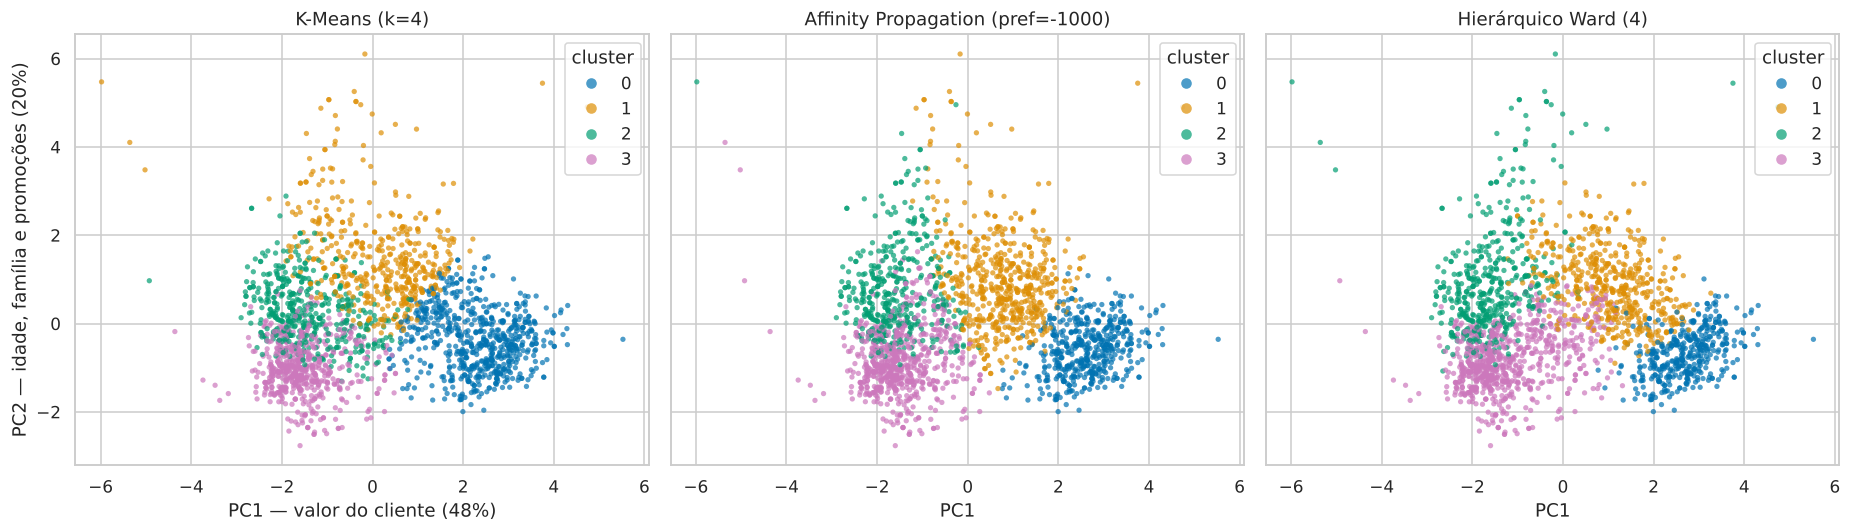

In [26]:
pcs = pca.transform(X_scaled)[:, :2]
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, (nome, col) in zip(axes, modelos.items()):
    sns.scatterplot(data=df, x="PC1", y="PC2", hue=col, palette=CORES, s=12, alpha=.7,
                    linewidth=0, ax=ax)
    ax.set_title(nome)
    ax.legend(title="cluster", loc="upper right", markerscale=2)
axes[0].set_xlabel(f"PC1 — valor do cliente ({var[0]:.0%})")
axes[0].set_ylabel(f"PC2 — idade, família e promoções ({var[1]:.0%})")
plt.tight_layout()
plt.show()

Os clusters aparecem como regiões vizinhas sem espaço vazio entre elas, o que é coerente com o silhouette moderado. O cluster 0 (maior gasto) ocupa a direita do PC1; os clusters de gasto baixo ficam à esquerda e se separam entre si pelo PC2.

## 9. Interpretação dos segmentos (K-Means)

### 9.1 Perfil médio

In [27]:
perfil_cols = features + ["Kidhome", "Teenhome", "Tenure_days", "Recency"]
perfil = df.groupby("cluster_kmeans")[perfil_cols].mean().T
perfil.columns = [f"cluster {c}" for c in perfil.columns]
perfil["média geral"] = df[perfil_cols].mean()
perfil.loc["clientes"] = df["cluster_kmeans"].value_counts().sort_index().values.tolist() + [len(df)]
perfil

,cluster 0,cluster 1,cluster 2,cluster 3,média geral
Income,"75,103.54","57,378.69","41,653.96","30,186.75","51,958.81"
Age,46.57,48.03,50.96,36.69,45.09
Children,0.27,1.27,1.77,0.80,0.95
Spent,"1,278.34",775.81,124.14,107.83,607.27
Purchases,19.11,17.51,6.65,6.06,12.57
NumDealsPurchases,1.19,4.74,2.28,1.73,2.32
NumWebVisitsMonth,2.88,6.35,5.88,6.78,5.32
Kidhome,0.03,0.35,0.78,0.71,0.44
Teenhome,0.25,0.93,0.99,0.09,0.51
Tenure_days,341.29,433.64,295.77,349.54,353.71


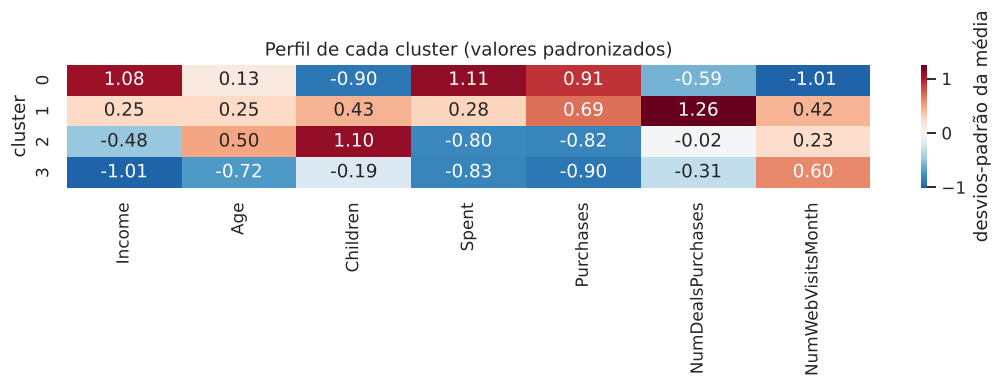

In [28]:
perfil_z = pd.DataFrame(X_scaled, columns=features).groupby(df["cluster_kmeans"]).mean()
plt.figure(figsize=(10, 3.4))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "desvios-padrão da média"})
plt.title("Perfil de cada cluster (valores padronizados)")
plt.ylabel("cluster")
plt.tight_layout()
plt.show()

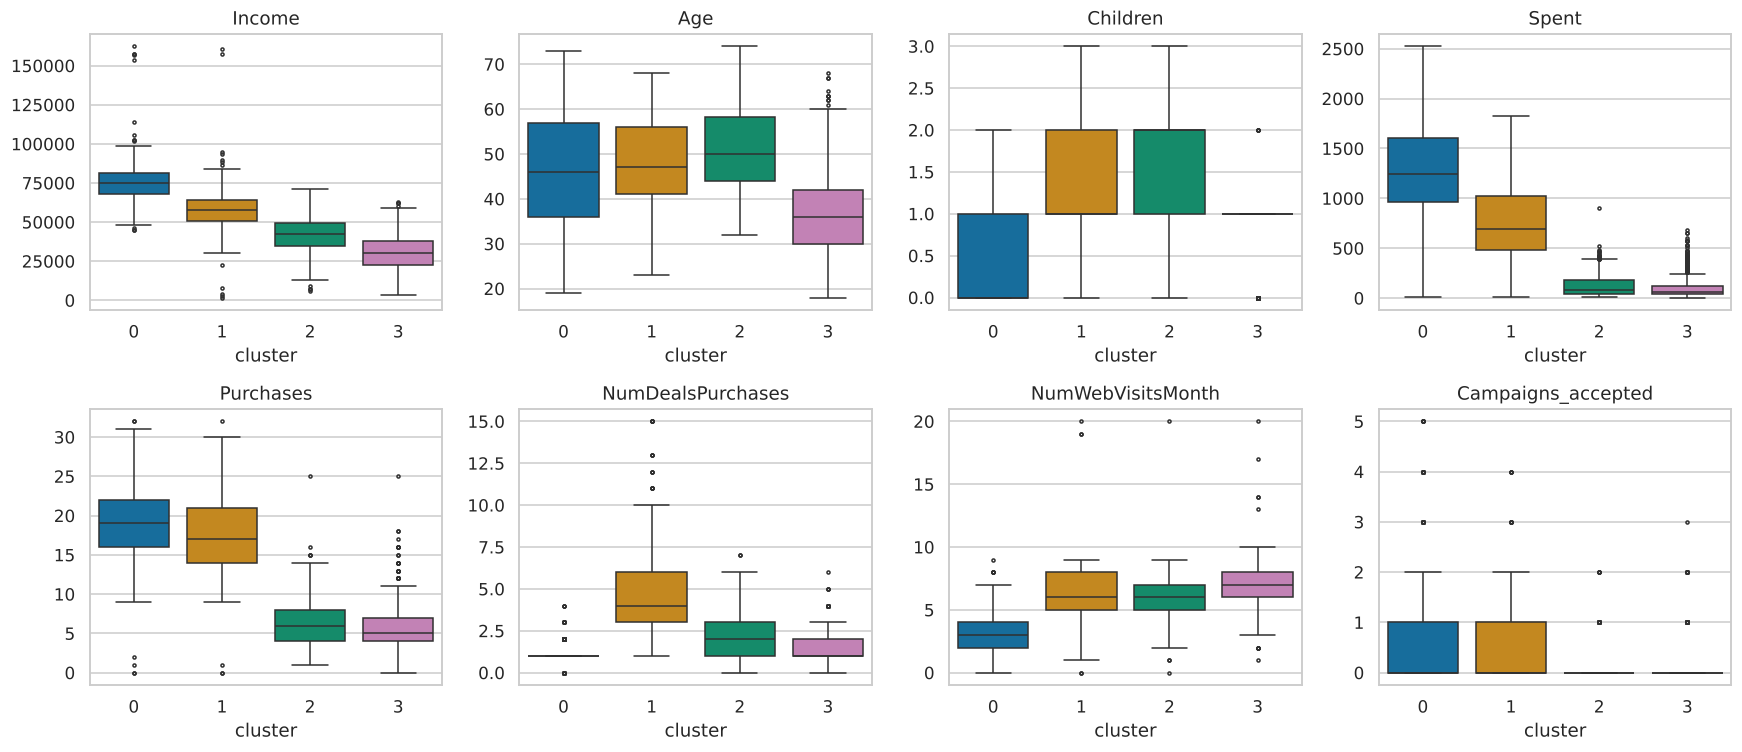

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features + ["Campaigns_accepted"]):
    sns.boxplot(data=df, x="cluster_kmeans", y=col, palette=CORES, ax=ax, fliersize=2)
    ax.set_title(col); ax.set_xlabel("cluster"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 9.2 O que cada segmento compra e por onde

Estas variáveis **não entraram no modelo**. Se os segmentos também diferem nelas, é sinal de que capturam comportamentos reais.

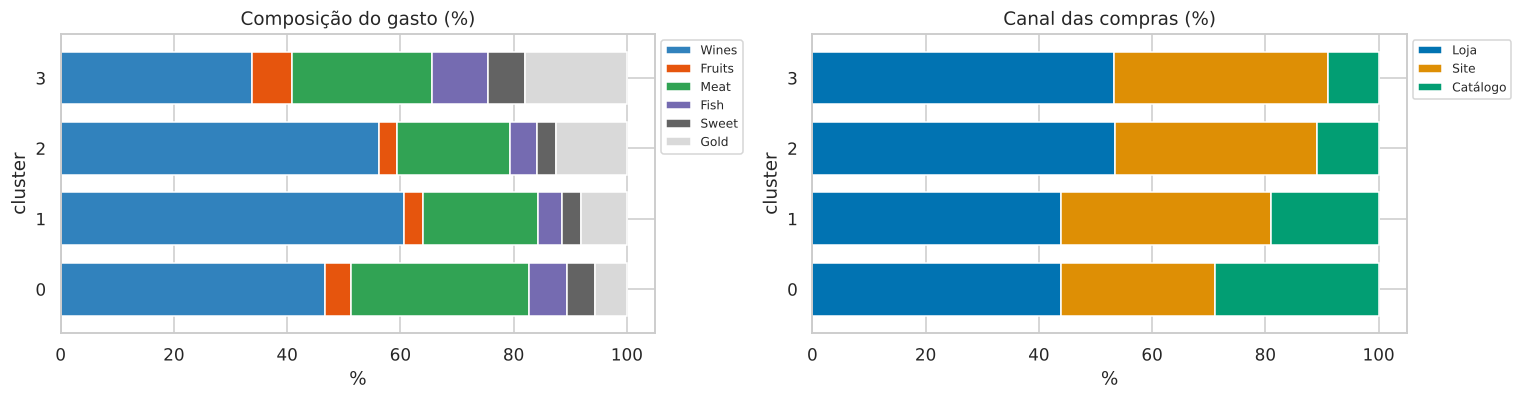

,Wines,Fruits,Meat,Fish,Sweet,Gold
cluster_kmeans,,,,,,
0,46.70,4.60,31.30,6.80,4.80,5.70
1,60.60,3.40,20.30,4.30,3.40,8.10
2,56.20,3.20,19.90,4.80,3.30,12.60
3,33.80,7.00,24.80,9.80,6.60,18.00


,Loja,Site,Catálogo
cluster_kmeans,,,
0,43.90,27.30,28.80
1,43.90,37.10,19.00
2,53.40,35.70,10.80
3,53.20,37.80,9.00


In [30]:
mix = df.groupby("cluster_kmeans")[mnt_cols].sum()
mix = mix.div(mix.sum(axis=1), axis=0) * 100
mix.columns = [c.replace("Mnt", "").replace("Products", "").replace("Prods", "") for c in mix.columns]

canal = df.groupby("cluster_kmeans")[["NumStorePurchases", "NumWebPurchases", "NumCatalogPurchases"]].sum()
canal = canal.div(canal.sum(axis=1), axis=0) * 100
canal.columns = ["Loja", "Site", "Catálogo"]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
mix.plot.barh(stacked=True, ax=axes[0], colormap="tab20c", width=.75)
axes[0].set(title="Composição do gasto (%)", xlabel="%", ylabel="cluster")
axes[0].legend(bbox_to_anchor=(1, 1), fontsize=8)
canal.plot.barh(stacked=True, ax=axes[1], color=["C0", "C1", "C2"], width=.75)
axes[1].set(title="Canal das compras (%)", xlabel="%", ylabel="cluster")
axes[1].legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.show()

display(mix.round(1))
display(canal.round(1))

### 9.3 Resposta às campanhas de marketing

Taxa de aceitação por campanha (%) — campanhas não usadas no modelo


,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response,aceitou alguma (%)
cluster_kmeans,,,,,,,
0,18.10,3.00,8.10,12.00,22.60,24.90,45.40
1,4.00,1.70,7.40,14.60,2.10,15.50,31.40
2,0.20,0.40,5.00,2.60,0.00,5.60,12.50
3,0.20,0.00,8.40,0.50,0.00,11.20,15.60


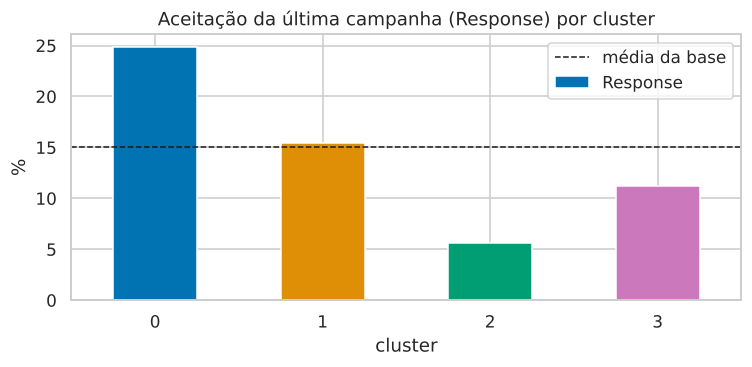

In [31]:
resp = df.groupby("cluster_kmeans")[cmp_cols].mean() * 100
resp["aceitou alguma (%)"] = df.groupby("cluster_kmeans")["Campaigns_accepted"].apply(lambda s: (s > 0).mean() * 100)
print("Taxa de aceitação por campanha (%) — campanhas não usadas no modelo")
display(resp.round(1))

plt.figure(figsize=(7, 3.5))
(df.groupby("cluster_kmeans")["Response"].mean() * 100).plot.bar(color=CORES, rot=0)
plt.axhline(df["Response"].mean() * 100, color="k", ls="--", lw=1, label="média da base")
plt.title("Aceitação da última campanha (Response) por cluster")
plt.ylabel("%"); plt.xlabel("cluster"); plt.legend()
plt.tight_layout()
plt.show()

### 9.4 Perfil demográfico

In [32]:
demo = pd.concat([
    pd.crosstab(df["cluster_kmeans"], df["Education_level"], normalize="index") * 100,
    (df.groupby("cluster_kmeans")["Couple"].mean() * 100).rename("Em casal (%)"),
    (df.groupby("cluster_kmeans")["Kidhome"].apply(lambda s: (s > 0).mean()) * 100).rename("Tem criança pequena (%)"),
    (df.groupby("cluster_kmeans")["Teenhome"].apply(lambda s: (s > 0).mean()) * 100).rename("Tem adolescente (%)"),
], axis=1)
demo.round(1)

,Básica,Graduação,Pós,Em casal (%),Tem criança pequena (%),Tem adolescente (%)
cluster_kmeans,,,,,,
0,0.00,61.80,38.20,62.40,2.80,24.40
1,0.20,56.10,43.60,66.50,33.10,87.10
2,0.40,55.40,44.20,65.10,70.30,94.20
3,8.40,62.20,29.40,65.00,70.70,9.40


### 9.5 Nomeando os segmentos

| Cluster | Nome | Quem são | Como compram | Como abordar |
|---|---|---|---|---|
| **0** | **Premium** | Maior renda (cerca de 75 mil), quase sem filhos em casa | Gastam cerca de 10 vezes mais que os segmentos de gasto baixo, sobretudo vinho e carne; são os que mais compram por catálogo e quase não usam desconto | Maior taxa de resposta às campanhas. Programas de fidelidade, lançamentos e produtos premium; promoção não é necessária. |
| **1** | **Famílias caçadoras de promoção** | Renda média (cerca de 57 mil), mais velhos, maioria com adolescentes em casa | Gasto intermediário, compram com frequência e são os que **mais usam desconto**; clientes há mais tempo | Cupons e combos para família. É o segmento que mais reage a preço. |
| **2** | **Famílias maiores, gasto baixo** | Os mais velhos da base (cerca de 51 anos), com mais filhos (quase 2 em média), renda de cerca de 42 mil | Gastam pouco e compram pouco | **Menor resposta às campanhas.** Antes de investir em campanha, entender o que os afasta (preço, mix de produtos). |
| **3** | **Jovens de renda baixa** | Os mais jovens (cerca de 37 anos), menor renda (cerca de 30 mil), filhos pequenos | Menor gasto da base, mas **visitam muito o site** sem converter; proporcionalmente gastam mais em itens "gold", peixe, frutas e doces e menos em vinho | Ações digitais (site, app, e-mail) para converter visitas em compras; produtos de entrada. |

Os gráficos das seções 9.2 a 9.4 sustentam essa leitura, e os números exatos estão nas tabelas.

In [33]:
nomes = {0: "Premium", 1: "Famílias caçadoras de promoção",
         2: "Famílias maiores, gasto baixo", 3: "Jovens de renda baixa"}
df["segmento"] = df["cluster_kmeans"].map(nomes)

resumo = df.groupby("segmento").agg(
    clientes=("ID", "count"),
    renda_media=("Income", "mean"),
    gasto_medio=("Spent", "mean"),
    filhos=("Children", "mean"),
    idade=("Age", "mean"),
    resposta_ultima_campanha_pct=("Response", lambda s: s.mean() * 100),
)
resumo["participacao_no_faturamento_pct"] = df.groupby("segmento")["Spent"].sum() / df["Spent"].sum() * 100
resumo.sort_values("gasto_medio", ascending=False)

,clientes,renda_media,gasto_medio,filhos,idade,resposta_ultima_campanha_pct,participacao_no_faturamento_pct
segmento,,,,,,,
Premium,668,"75,103.54","1,278.34",0.27,46.57,24.85,63.57
Famílias caçadoras de promoção,472,"57,378.69",775.81,1.27,48.03,15.47,27.26
"Famílias maiores, gasto baixo",464,"41,653.96",124.14,1.77,50.96,5.60,4.29
Jovens de renda baixa,608,"30,186.75",107.83,0.80,36.69,11.18,4.88


## 10. Conclusões

**O que encontramos**

1. A base se divide em **4 segmentos interpretáveis**: Premium, Famílias caçadoras de promoção, Famílias maiores com gasto baixo e Jovens de renda baixa.
2. **Renda e número de filhos são os fatores que mais separam os clientes.** O PC1 (valor do cliente) explica quase metade da variância.
3. Os segmentos diferem também em variáveis que **não entraram no modelo** — mix de produtos, canal de compra e resposta às campanhas —, o que indica que eles capturam comportamentos reais e não apenas recortes arbitrários.
4. O segmento Premium é uma minoria dos clientes mas concentra a maior parte do faturamento (ver a tabela-resumo), e é também o que mais responde às campanhas.
5. K-Means, Affinity Propagation e o hierárquico chegam a estruturas parecidas. O Affinity Propagation só chegou a um número útil de grupos depois de ajustarmos o `preference`.

**Limitações**

- **Os clusters não são bem separados** (silhouette em torno de 0,26). Os clientes formam um contínuo, e quem está perto das fronteiras poderia cair em outro segmento.
- **Escolhemos k = 4 por utilidade de negócio, não pela melhor métrica**: k = 2 e k = 3 tinham silhouette maior.
- **As features e a forma de limpeza foram decisões nossas.** Outra seleção de variáveis levaria a outros segmentos.
- `Spent` e `Income` são assimétricas, e o K-Means é sensível a valores extremos.
- Os dados são de 2012 a 2014 e de uma única empresa; não sabemos o país nem a moeda.

**Próximos passos**

- Aplicar transformação logarítmica em `Spent` e `Income` e comparar os segmentos.
- Testar Gaussian Mixture, que dá a probabilidade de cada cliente pertencer a cada segmento (útil para os clientes de fronteira).
- Usar o segmento como variável em um modelo supervisionado para prever quem vai aceitar a próxima campanha.